#### Importing libraries

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading the data

In [63]:
path = '../data/raw/spotify_top_1000_tracks.csv'
df = pd.read_csv(path)

### **Data Cleanup**

#### Making sure duration_min and popularity are numeric

In [64]:
df['duration_min'] = pd.to_numeric(df['duration_min'], errors='coerce')
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

#### Converting release_date to datetime object

In [65]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

#### Extracting the "release_year" in a new column for easier analysis

In [66]:
df['release_year'] = df['release_date'].dt.year

#### Dropping the few rows that might got failed conversion

In [67]:
df = df.dropna(subset=['release_year', 'duration_min', 'popularity'])

#### Checking data to ensure all the operations were successful

In [68]:
df.info()

<class 'pandas.DataFrame'>
Index: 977 entries, 0 to 999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   track_name    977 non-null    str           
 1   artist        977 non-null    str           
 2   album         977 non-null    str           
 3   release_date  977 non-null    datetime64[us]
 4   popularity    977 non-null    int64         
 5   spotify_url   977 non-null    str           
 6   id            977 non-null    str           
 7   duration_min  977 non-null    float64       
 8   release_year  977 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(5)
memory usage: 188.5 KB


### Data Visualization

#### Are hit songs getting shorter over the years?

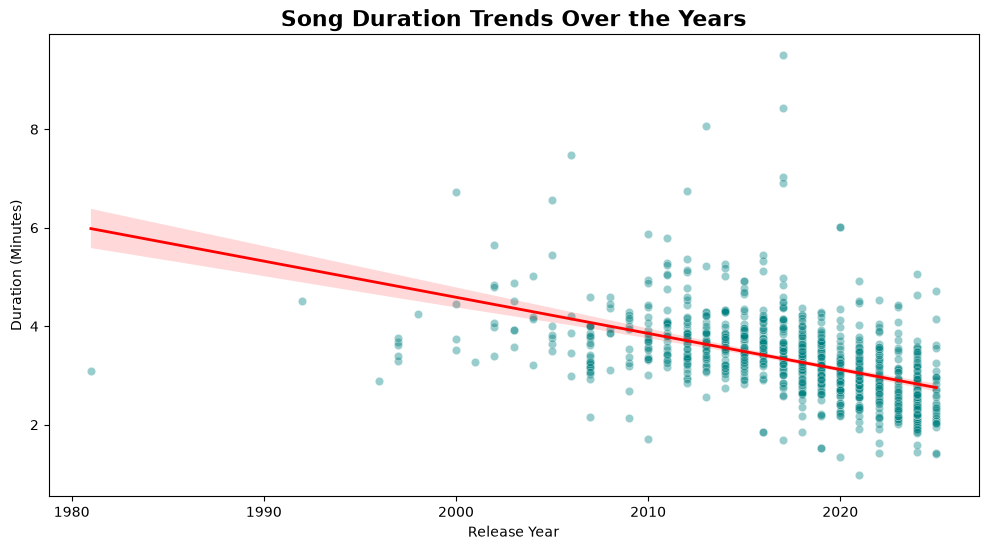

In [69]:
plt.figure(figsize=(12, 6))


# We use a hexbin or scatter with low alpha because 1000 points can get messy
sns.scatterplot(data=df, x='release_year', y='duration_min', alpha=0.4, color='teal')


# Adding a trend line to see the overall direction over the years
sns.regplot(data=df, x='release_year', y='duration_min', scatter=False, color='red', line_kws={'linewidth': 2})


plt.title('Song Duration Trends Over the Years', fontsize=16, fontweight='bold')
plt.xlabel('Release Year')
plt.ylabel('Duration (Minutes)')


plt.savefig('../images/duration_trend.png', dpi=300, bbox_inches='tight')
plt.show()

#### Who were the Top 10 Most Frequent Artists?

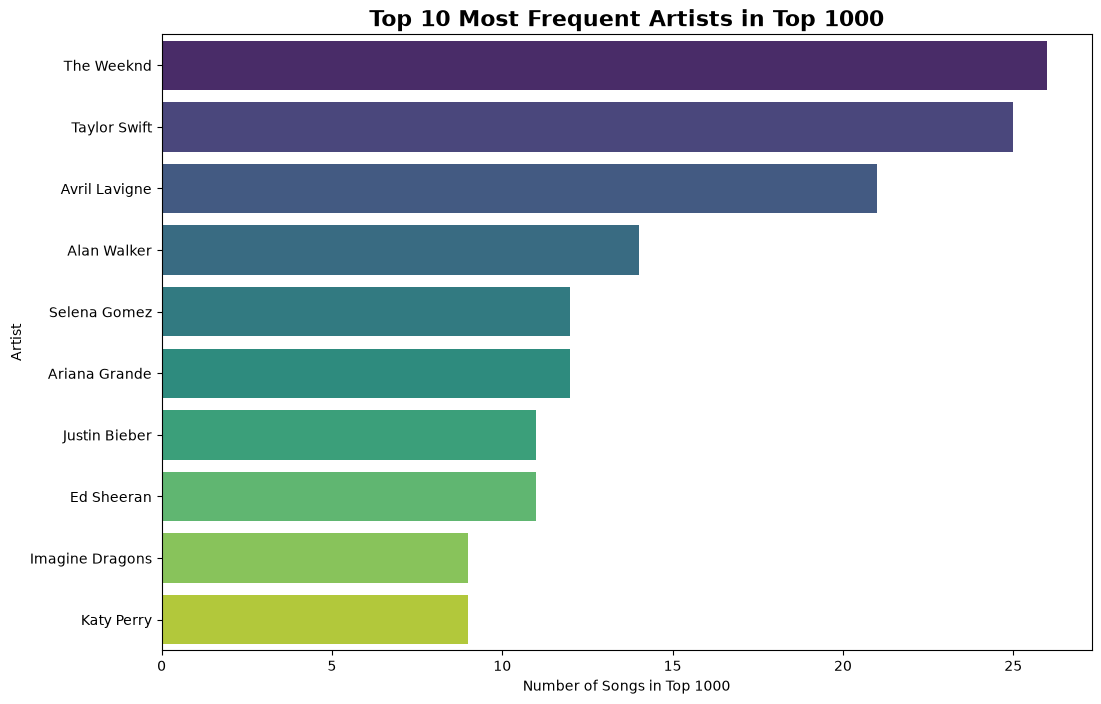

In [71]:
plt.figure(figsize=(12, 8))


# Counting how many times each artist appears in the Top 1000
top_artists = df['artist'].value_counts().head(10).reset_index()
top_artists.columns = ['Artist', 'Count']


sns.barplot(data=top_artists, x='Count', y='Artist', palette='viridis', hue='Artist', legend=False)


plt.title('Top 10 Most Frequent Artists in Top 1000', fontsize=16, fontweight='bold')
plt.xlabel('Number of Songs in Top 1000')
plt.ylabel('Artist')


plt.savefig('../images/top_artists_count.png', dpi=300, bbox_inches='tight')
plt.show()

####  Does "Popularity" correlate with song length?

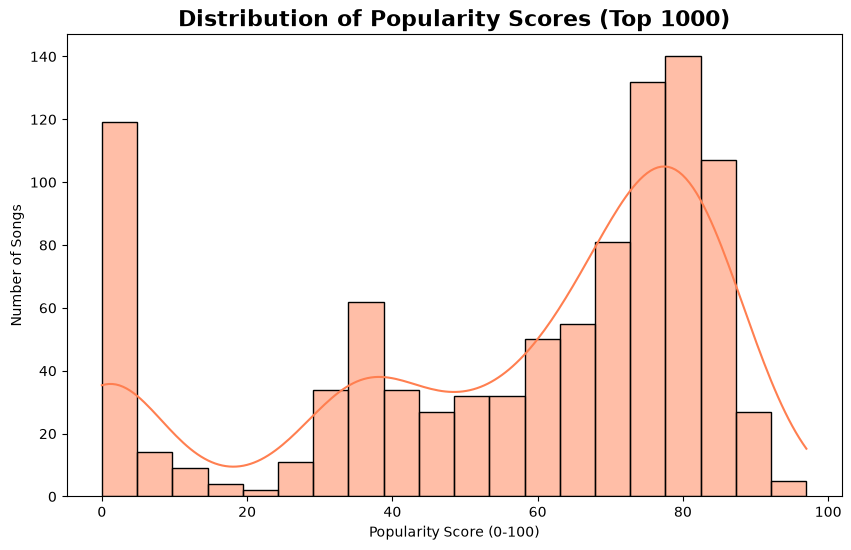

In [72]:
plt.figure(figsize=(10, 6))


# Histogram of popularity scores
sns.histplot(data=df, x='popularity', bins=20, kde=True, color='coral')


plt.title('Distribution of Popularity Scores (Top 1000)', fontsize=16, fontweight='bold')
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Number of Songs')


plt.savefig('../images/popularity_distribution.png', dpi=300, bbox_inches='tight')
plt.show()